In [1]:
import os
import glob
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: []


2026-10-18 15:53:53.569491: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:
DATA_PATH = (
    "/kaggle/input/datasets/"
    "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"
)

# Find CSV files inside the dataset directory
csv_files = glob.glob(
    os.path.join(DATA_PATH, "**", "*.csv"),
    recursive=True
)

print("CSV files found:", csv_files)

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found. Check the Kaggle dataset path."
    )

# Load the first CSV file
df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

CSV files found: ['/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv']
Dataset loaded successfully!
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all"))

Number of rows and columns: (50000, 2)

Column names:
['review', 'sentiment']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 418

Statistical summary:


,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [4]:
# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Check the required columns
required_columns = {"review", "sentiment"}

if not required_columns.issubset(df.columns):
    raise ValueError(
        f"Expected columns {required_columns}, "
        f"but found {df.columns.tolist()}"
    )

# Remove rows with missing values in required columns
df = df.dropna(subset=["review", "sentiment"]).copy()

# Remove exact duplicate rows
df = df.drop_duplicates(subset=["review", "sentiment"]).copy()

df["review"] = df["review"].astype(str).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

# Keep valid binary sentiment labels
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

# Remove empty reviews
df = df[df["review"] != ""].copy()

print("Cleaned dataset shape:", df.shape)
print("\nSentiment labels:")
print(df["sentiment"].value_counts())

Cleaned dataset shape: (49582, 2)

Sentiment labels:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


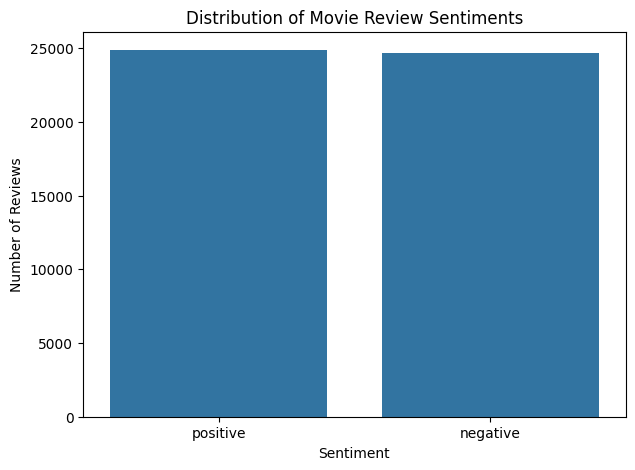

sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [5]:
sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sentiment")
plt.title("Distribution of Movie Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

print(sentiment_counts)


,review,sentiment,review_length
0,One of the other reviewers has mentioned that ...,positive,307
1,A wonderful little production. <br /><br />The...,positive,162
2,I thought this was a wonderful way to spend ti...,positive,166
3,Basically there's a family where a little boy ...,negative,138
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,230


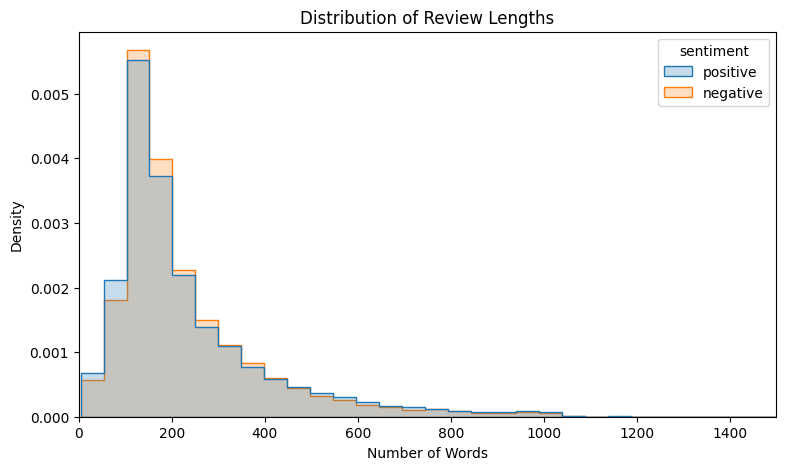

count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: review_length, dtype: float64


In [6]:
df["review_length"] = df["review"].apply(
    lambda text: len(text.split())
)

display(df[["review", "sentiment", "review_length"]].head())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.xlim(0, 1500)
plt.show()

print(df["review_length"].describe())

In [7]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review_clean"] = df["review"].apply(clean_text)

display(df[["review", "review_clean", "sentiment"]].head())

,review,review_clean,sentiment
0,One of the other reviewers has mentioned that ...,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,A wonderful little production. The filming tec...,positive
2,I thought this was a wonderful way to spend ti...,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...","Petter Mattei's ""Love in the Time of Money"" is...",positive


In [8]:
label_map = {
    "negative": 0,
    "positive": 1
}

df["label"] = df["sentiment"].map(label_map)

print(df[["sentiment", "label"]].head(10))
print("\nLabel counts:")
print(df["label"].value_counts())

  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1
5  positive      1
6  positive      1
7  negative      0
8  negative      0
9  positive      1

Label counts:
label
1    24884
0    24698
Name: count, dtype: int64


In [9]:
X = df["review_clean"].to_numpy()
y = df["label"].to_numpy()

# First: reserve 20% for final testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second: reserve 10% of the full dataset for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.125,
    random_state=42,
    stratify=y_train_val
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 34706
Validation samples: 4959
Testing samples: 9917


In [10]:
MAX_TOKENS = 30000
MAX_LENGTH = 300

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    standardize="lower_and_strip_punctuation"
)

# Learn vocabulary from training reviews only
train_text_ds = tf.data.Dataset.from_tensor_slices(
    X_train
).batch(256)

vectorizer.adapt(train_text_ds)

print("Vocabulary size:", vectorizer.vocabulary_size())

# Convert reviews to integer sequences
X_train_seq = vectorizer(
    tf.constant(X_train)
).numpy()

X_val_seq = vectorizer(
    tf.constant(X_val)
).numpy()

X_test_seq = vectorizer(
    tf.constant(X_test)
).numpy()

print("Training sequence shape:", X_train_seq.shape)
print("Example sequence:")
print(X_train_seq[0][:30])

Vocabulary size: 30000
Training sequence shape: (34706, 300)
Example sequence:
[   40    38   231   149  1432  4929   165   149  2834  3320    13     1
    32    33 18378  7548   921     2  1442   197   231   149     4    11
   149   921   189    13     2   733]


In [11]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout,
    SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Embedding(
        input_dim=vectorizer.vocabulary_size(),
        output_dim=128,
        mask_zero=False
    ),

    SpatialDropout1D(0.2),

    Conv1D(
        filters=128,
        kernel_size=5,
        activation="relu",
        padding="valid"
    ),

    GlobalMaxPooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=8,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/8
272/272 ━━━━━━━━━━━━━━━━━━━━ 77s 276ms/step - accuracy: 0.7511 - loss: 0.4825 - val_accuracy: 0.8657 - val_loss: 0.3084
Epoch 2/8
272/272 ━━━━━━━━━━━━━━━━━━━━ 72s 266ms/step - accuracy: 0.9117 - loss: 0.2299 - val_accuracy: 0.8838 - val_loss: 0.2815
Epoch 3/8
272/272 ━━━━━━━━━━━━━━━━━━━━ 71s 262ms/step - accuracy: 0.9643 - loss: 0.1089 - val_accuracy: 0.8881 - val_loss: 0.2958
Epoch 4/8
272/272 ━━━━━━━━━━━━━━━━━━━━ 71s 262ms/step - accuracy: 0.9899 - loss: 0.0401 - val_accuracy: 0.8855 - val_loss: 0.3570


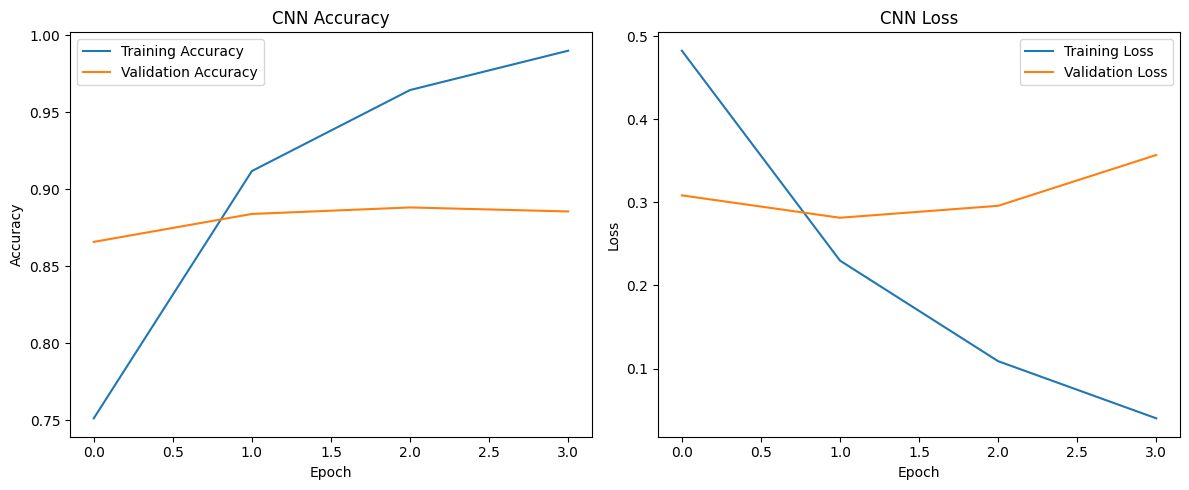

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
test_loss, test_accuracy = model.evaluate(
    X_test_seq,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")

310/310 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8942 - loss: 0.2602
Test Loss: 0.2602
Test Accuracy: 0.8942
Test Accuracy Percentage: 89.42%


In [15]:
y_probability = model.predict(
    X_test_seq,
    batch_size=256,
    verbose=1
).ravel()

y_pred = (y_probability >= 0.5).astype(int)

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        digits=4
    )
)

39/39 ━━━━━━━━━━━━━━━━━━━━ 5s 137ms/step
              precision    recall  f1-score   support

    Negative     0.8745    0.9196    0.8965      4940
    Positive     0.9159    0.8690    0.8918      4977

    accuracy                         0.8942      9917
   macro avg     0.8952    0.8943    0.8942      9917
weighted avg     0.8953    0.8942    0.8942      9917



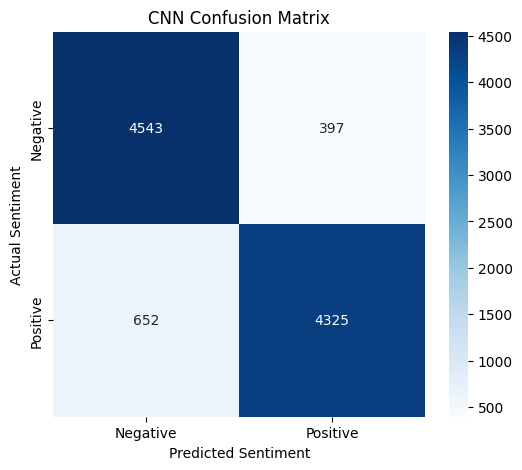

In [16]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("CNN Confusion Matrix")
plt.show()

In [17]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)

    sequence = vectorizer(
        tf.constant([cleaned_review])
    )

    probability = float(
        model.predict(sequence, verbose=0)[0][0]
    )

    sentiment = (
        "Positive" if probability >= 0.5
        else "Negative"
    )

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probability:.2%}")


predict_sentiment(
    "This movie was wonderful, emotional, and beautifully directed."
)

predict_sentiment(
    "This movie was boring, disappointing, and a complete waste of time."
)

Review: This movie was wonderful, emotional, and beautifully directed.
Predicted sentiment: Positive
Positive probability: 99.94%
Review: This movie was boring, disappointing, and a complete waste of time.
Predicted sentiment: Negative
Positive probability: 0.00%


In [18]:
# Save the trained CNN
model.save("/kaggle/working/imdb_cnn_model.keras")

# Save the learned text vocabulary
vocabulary = vectorizer.get_vocabulary()

pd.DataFrame({
    "token": vocabulary
}).to_csv(
    "/kaggle/working/imdb_vocabulary.csv",
    index=False
)

print("Model and vocabulary saved successfully!")

Model and vocabulary saved successfully!
